In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Create output folder
os.makedirs("Prescription_Visualization_Output", exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving HospitalOPD_CareFlow_cleaned_v4.xlsx to HospitalOPD_CareFlow_cleaned_v4.xlsx


In [3]:

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name, sheet_name="Cleaned_Data")

# Convert prescription dates
df["prescription_start_datetime"] = pd.to_datetime(
    df["prescription_start_datetime"], errors="coerce"
)

df["prescription_end_datetime"] = pd.to_datetime(
    df["prescription_end_datetime"], errors="coerce"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (62422, 50)


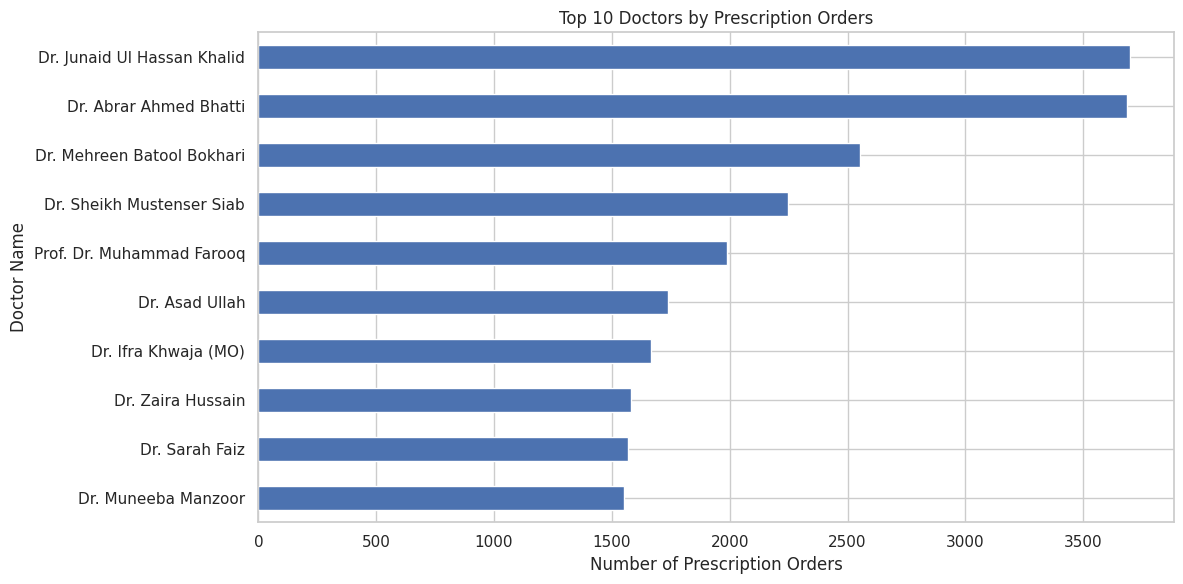

In [4]:

doctor_data = (
    df.groupby("prescription_doctor_name")["prescription_order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
doctor_data.sort_values().plot(kind="barh")

plt.title("Top 10 Doctors by Prescription Orders")
plt.xlabel("Number of Prescription Orders")
plt.ylabel("Doctor Name")
plt.tight_layout()

plt.savefig(
    "Prescription_Visualization_Output/doctor_analysis.png",
    dpi=300
)
plt.show()


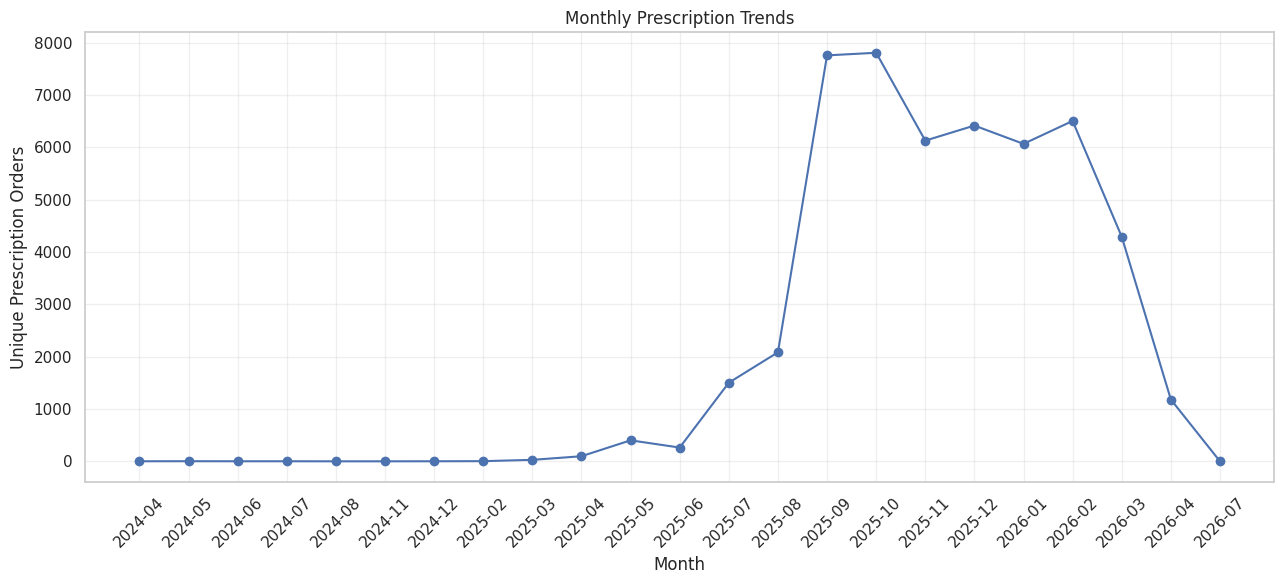

In [12]:

# Corrected Monthly Prescription Trends

monthly_data = df.dropna(
    subset=[
        "prescription_start_datetime",
        "prescription_order_id"
    ]
).copy()

monthly_data["Month"] = (
    monthly_data["prescription_start_datetime"]
    .dt.to_period("M").astype(str)
)

monthly_orders = (
    monthly_data.groupby("Month")["prescription_order_id"]
    .nunique()
)

plt.figure(figsize=(13, 6))
plt.plot(monthly_orders.index, monthly_orders.values, marker="o")

plt.title("Monthly Prescription Trends")
plt.xlabel("Month")
plt.ylabel("Unique Prescription Orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Prescription_Visualization_Output/monthly_trends.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


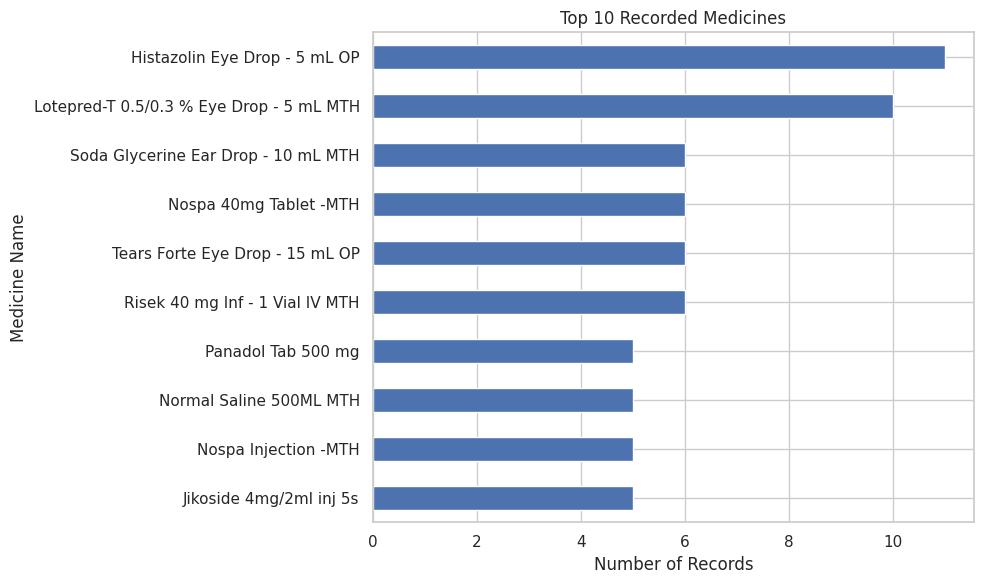

In [6]:

medicine_data = (
    df["medicine_name"]
    .dropna()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
medicine_data.sort_values().plot(kind="barh")

plt.title("Top 10 Recorded Medicines")
plt.xlabel("Number of Records")
plt.ylabel("Medicine Name")
plt.tight_layout()

plt.savefig(
    "Prescription_Visualization_Output/medicine_distribution.png",
    dpi=300
)
plt.show()


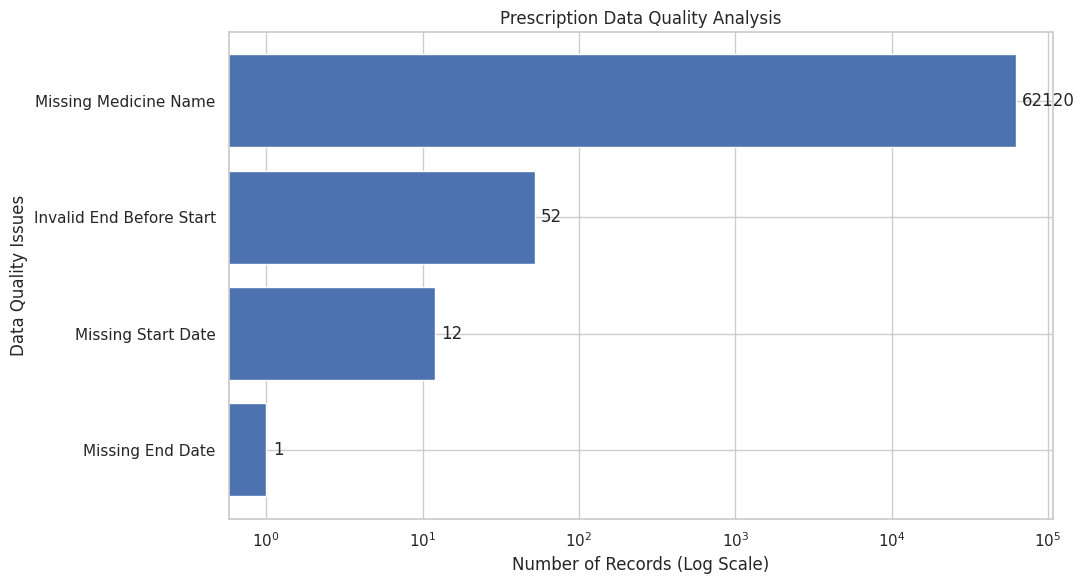

In [13]:

# Improved Prescription Data Quality Chart

invalid_flags = (
    df["flag_prescription_end_before_start"]
    .astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"])
)

quality_data = pd.Series({
    "Missing Start Date": df["prescription_start_datetime"].isna().sum(),
    "Missing End Date": df["prescription_end_datetime"].isna().sum(),
    "Missing Medicine Name": df["medicine_name"].isna().sum(),
    "Invalid End Before Start": invalid_flags.sum()
}).sort_values()

plt.figure(figsize=(11, 6))

bars = plt.barh(
    quality_data.index,
    quality_data.values
)

plt.xscale("log")
plt.title("Prescription Data Quality Analysis")
plt.xlabel("Number of Records (Log Scale)")
plt.ylabel("Data Quality Issues")

for bar, value in zip(bars, quality_data.values):
    plt.text(
        value * 1.1,
        bar.get_y() + bar.get_height()/2,
        str(value),
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "Prescription_Visualization_Output/data_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


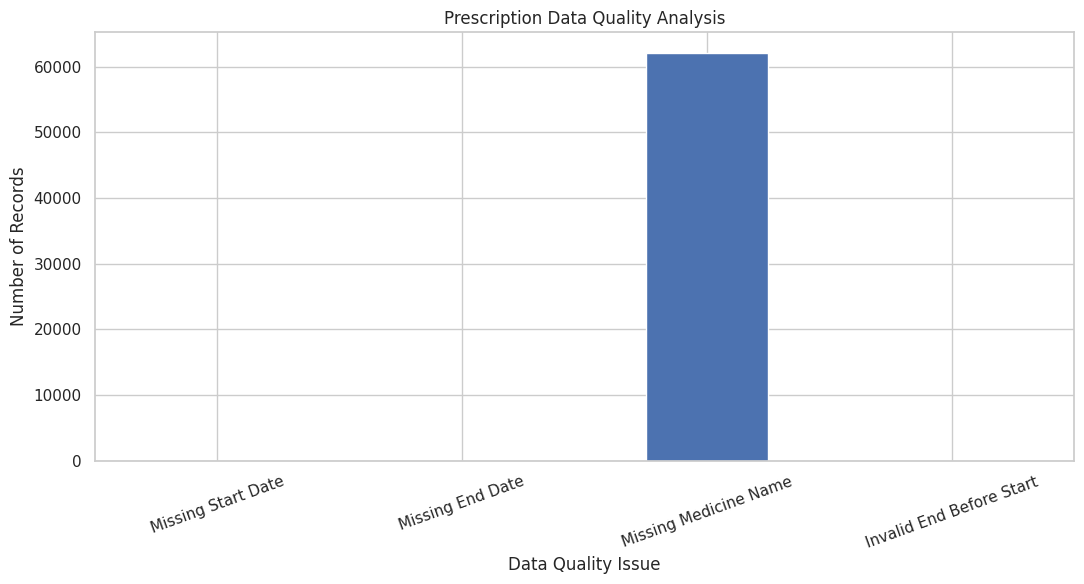

In [7]:

quality_data = pd.Series({
    "Missing Start Date": df["prescription_start_datetime"].isna().sum(),
    "Missing End Date": df["prescription_end_datetime"].isna().sum(),
    "Missing Medicine Name": df["medicine_name"].isna().sum(),
    "Invalid End Before Start": (
        df["flag_prescription_end_before_start"].eq(True).sum()
    )
})

plt.figure(figsize=(11, 6))
quality_data.plot(kind="bar")

plt.title("Prescription Data Quality Analysis")
plt.xlabel("Data Quality Issue")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "Prescription_Visualization_Output/data_quality.png",
    dpi=300
)
plt.show()


In [14]:

import shutil

shutil.make_archive(
    "Prescription_Visualization_Output",
    "zip",
    "Prescription_Visualization_Output"
)

files.download("Prescription_Visualization_Output.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>